# 05: An LSTM, measured by the same rule

Notebook 04 compared five models, and the consensus of CLIPER and XGBoost came first. This notebook
adds a neural network that reads each storm's track one fix at a time, and asks two questions: does it
add anything beyond XGBoost, and does the leader change under the rule in `CLAUDE.md`?

Two new candidates join the race, both written into the test plan before any LSTM was fitted:
`lstm`, and `consensus_lstm`, the average of the CLIPER, XGBoost and LSTM positions.

All the logic lives in `src/cyclone/`, and `docs/components.md` explains each module. This notebook only
calls it in order: load → build sequences → search → forecast → score → decide → fit the final models.

**Only the development seasons, 1980–2017, are used. The test split stays locked.** No forecast is made
for a test storm here. The last section builds the final models and rehearses test day on development
seasons. Test is scored once, at the end of Project 1.

**Running locally:** use the `cyclone` kernel after `pip install -e .`, with PyTorch installed as `CLAUDE.md`
describes. Run notebook 01 first, because this one reads `ni_clean.parquet`. With everything already
saved it takes about 2 minutes on a laptop CPU. On a fresh machine, add about 10 minutes for the XGBoost
searches, 10 for the LSTM search and 5 to fit the networks.

**Running on Colab:** run these in a first cell:

```python
!git clone https://github.com/Anshuman-Alok-Gupta/Cyclone_Project.git
!pip install -e Cyclone_Project
```

Then choose *Runtime → Restart session*, because Python only finds a newly installed
editable package when it starts. After the restart, run this before the cells below:

```python
from google.colab import drive
drive.mount("/content/drive")

import os
os.environ["CYCLONE_DATA_DIR"] = "/content/drive/MyDrive/cyclone-project/data"
```

PyTorch comes with Colab. Progress is saved to that Drive folder after every network, so a dropped
session loses one fit at most: run the notebook again with `RESUME = True`.

In [1]:
import pandas as pd

from cyclone import config, cv, final_model, final_scoring, lstm_model, xgb_model
from cyclone.baselines import cliper_forecast, persistence_forecast
from cyclone.checks import check_expected, check_samples, check_sequences
from cyclone.consensus import CONSENSUS_LSTM_NAME, CONSENSUS_NAME, consensus
from cyclone.features import build_features
from cyclone.folds import FOLD_NAMES, FOLD_SEASONS
from cyclone.plotting import plot_forecasts
from cyclone.samples import make_init_times, make_truth
from cyclone.scoring import score, summarize
from cyclone.sequences import STEP_COLUMNS, build_sequences

## What the LSTM reads

XGBoost gets one row of numbers per start time, so someone had to decide what to summarize: motion over
6, 12 and 24 h, and so on. An LSTM reads the fixes in order and works out its own summary, so it's handed
the track itself. For each start time, that's the storm's JTWC fixes from up to 72 h before t0 up to t0.

**Exactly the same start times as every other model.** Models can only be compared on identical cases, so
a sequence is built for each row the other models use. `check_sequences` confirms it: the same start times in
the same order, each sequence ending at its own position, and the verified case counts of 2,953, 2,209 and 1,580.

**Nothing after t0.** Only fixes at t0 or earlier are read, and `sequences.py` never sees the truth table.
A test rewrites every fix after t0 and requires the sequences to stay identical.

**Each step** holds the 6 h change in latitude and longitude, latitude, longitude, wind, and a "wind
missing" flag. **Each forecast** also has day of year (as sin and cos, because it's a circle) and distance
to land at t0. Those go in after the LSTM, since they don't change along a sequence.

In [2]:
df = pd.read_parquet(config.ni_clean_path())
check_expected(df)

truth = make_truth(df)
init_times = make_init_times(df)
check_samples(init_times, truth)

rows = cv.model_rows(init_times, build_features(init_times), df)
sequences = build_sequences(rows, df)
check_sequences(sequences, rows, df, truth)

print("\nFixes in a sequence, and how many start times have that many:")
pd.Series(sequences.lengths).value_counts().sort_index().rename_axis("fixes").rename("start times").to_frame().T

Counts match: 5,694 rows, 258 storms, 184/27/47 train/val/test.
Sample counts match: 4,678 init times.
  train 3,203 init times; cases +24 h 2,515, +48 h 1,869, +72 h 1,324
  val     542 init times; cases +24 h 438, +48 h 340, +72 h 256
  test    933 init times; cases +24 h 749, +48 h 578, +72 h 430


Fold counts match: 211 storms, 3,745 init times.
  1980-1987   39 storms,  598 init times; cases +24 h 452, +48 h 324, +72 h 218
  1988-1995   44 storms,  774 init times; cases +24 h 617, +48 h 465, +72 h 325
  1996-2003   48 storms,  952 init times; cases +24 h 774, +48 h 605, +72 h 463
  2004-2010   43 storms,  737 init times; cases +24 h 570, +48 h 413, +72 h 284
  2011-2017   37 storms,  684 init times; cases +24 h 540, +48 h 402, +72 h 290
Sequences match: 3,745 start times, 5 to 13 steps.

Fixes in a sequence, and how many start times have that many:


fixes,5,6,7,8,9,10,11,12,13
start times,201,199,198,196,194,187,184,179,2207


Most sequences reach the limit of 13 fixes (72 h). The shorter ones are from early in a storm's life, and
none is shorter than 5, because every start time has a full 24 h of history. If a fix is missing, the
sequence starts after the gap: what's before it isn't a steady 6 h history.

Here's one real sequence, as the network receives it before scaling. It's Hudhud on 9 October 2014.

In [3]:
hudhud_sid = df[(df["NAME"] == "HUDHUD") & (df["SEASON"] == 2014)]["SID"].iloc[0]
hudhud_start = pd.Timestamp("2014-10-09 00:00")

number = rows.index[(rows["SID"] == hudhud_sid) & (rows["init_time"] == hudhud_start)][0]
pd.DataFrame(sequences.steps[number, : sequences.lengths[number]], columns=STEP_COLUMNS).round(2)

,dlat,dlon,lat,lon,wind,wind_missing
0,NaN,NaN,10.7,96.1,15.0,0.0
1,0.0,-0.2,10.7,95.9,20.0,0.0
2,0.1,-0.3,10.8,95.6,25.0,0.0
3,0.2,-0.4,11.0,95.2,25.0,0.0
4,0.2,-0.5,11.2,94.7,25.0,0.0
5,0.2,-0.5,11.4,94.2,30.0,0.0
6,0.4,-0.7,11.8,93.5,30.0,0.0
7,0.4,-0.8,12.2,92.7,35.0,0.0
8,0.4,-1.0,12.6,91.7,40.0,0.0
9,0.4,-1.0,13.0,90.7,45.0,0.0


**The blanks.** The first row's change is blank, because no fix comes before it in the sequence. A missing
wind is blank too, for the two storms in 1980 with none on record.

XGBoost can take a blank, because a tree just sends it down one side of a question. An LSTM can't: it
multiplies every input by a weight, and one blank turns everything after it blank. So each blank is filled
with the average, and for wind a separate 0/1 flag says so at each step. The fill keeps the arithmetic
working. The flag keeps it honest, because the network can tell a real average wind from an invented one,
and learn to ignore the wind where the flag is on. The first change needs no flag, since it's always the
first step.

**Scaling** puts the inputs on similar ranges: each has its mean subtracted and is divided by its spread.
Latitude averages about 13 and distance to land about 270 km, while a 6 h change is under 1. The network
starts with small random weights and adjusts them all at the same rate, so large inputs would swamp small
ones.

**Scaling has to be fitted on the learning rows only, inside each fold.** A mean and a spread are learned from
data, just as a weight is. If they were fitted on all rows, the held-out block's storms would have shaped how
every input is read, and a block's forecast would depend on its own storms. A test watches the scaler in
every fold, and requires it to see that fold's learning storms and nothing else.

## Search for the LSTM's settings

Twelve combinations of hidden size (how many numbers the memory holds), layers, dropout, learning rate and
weight decay run through all five folds on one seed. They're judged by the same relative-error rule as XGBoost's
search, through the same code. Fully random draws would have given hidden size 16 eight times and 32 once, so
each value of each setting is used equally often, in random pairings.

**How stopping works here.** Training too long makes a network memorize its storms. Early stopping watches
some storms it doesn't learn from, and keeps the weights from its best epoch. The held-out block can't be those
storms: its own answers would then shape the forecast being scored. So about 15% of the learning storms are set
aside, chosen whole. This is allowed because their answers already belong to the fold. Nothing from the held-out
block is involved, and what's carried to the final model is the rule, not a number of epochs.

`RESUME = True` reads the saved results back rather than searching again. After a change to the data or
inputs, set it to `False`.

In [4]:
RESUME = True

device = xgb_model.pick_device()
lstm_device = lstm_model.pick_device()
lstm_dir = config.lstm_dir()

lstm_search = lstm_model.search_cv(
    rows, truth, sequences, lstm_device, checkpoint=lstm_dir / "search.csv", resume=RESUME
)
lstm_settings = lstm_model.best_settings(lstm_search)
print("LSTM:", lstm_settings)
lstm_search.round(3)

Searching 12 combinations on cpu, 5 folds each
  Resuming: 12 combinations already done
LSTM: {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.2, 'learning_rate': 0.003, 'weight_decay': 0.1}


,hidden_size,num_layers,dropout,learning_rate,weight_decay,km_24h,km_48h,km_72h,relative_error
0,64,1,0.2,0.003,0.10,144.481,325.316,515.983,1.006
1,32,1,0.4,0.003,0.00,146.933,326.860,506.541,1.007
2,64,1,0.0,0.001,0.01,146.205,330.885,513.294,1.014
3,16,1,0.4,0.001,0.01,149.636,326.674,507.979,1.014
4,16,1,0.4,0.001,0.00,149.630,326.845,508.267,1.015
5,32,1,0.0,0.001,0.10,148.582,333.097,517.694,1.025
6,32,2,0.0,0.003,0.00,152.249,333.833,514.647,1.032
7,32,2,0.4,0.003,0.01,157.182,337.914,510.717,1.045
8,64,2,0.2,0.001,0.10,154.311,339.229,525.791,1.050
9,16,2,0.0,0.003,0.00,159.130,338.505,517.991,1.055


**One layer beat two every time:** all six one-layer combinations came ahead of all six with two. With a couple
of thousand cases, a bigger network has more to memorize and little more to find.

**The top of the table is close, and the order isn't firm.** The first two combinations are 0.1% apart on one
seed, and further down, one LSTM seed's score moves by nearly 3 points from the next. So this search can tell one
layer from two, but it can't really separate the top few. The test plan fixes the rule, so the winner stands.

## Forecast with all seven models

Every model takes the same route through `cv.out_of_fold`. XGBoost and `xgb_residual` use the settings chosen
in notebook 04, and every seeded model averages seeds 42 to 46. `consensus` and `consensus_lstm` have nothing to
fit, and their members are already out of fold, so their averages are too.

The LSTM is also run on the shorter sequences, for a check further down. Each fold's networks are saved as
they're fitted, so `RESUME = True` loads them.

In [5]:
final_dir = config.xgboost_final_dir()
xgboost_settings = xgb_model.best_settings(
    xgb_model.search_cv(
        rows, truth, device=device, checkpoint=final_dir / "search_xgboost.csv", resume=RESUME
    )
)
residual_settings = xgb_model.best_settings(
    xgb_model.search_cv(
        rows,
        truth,
        xgb_model.residual_forecaster,
        device=device,
        checkpoint=final_dir / "search_residual.csv",
        resume=RESUME,
    )
)

xgboost_forecaster = xgb_model.xgboost_forecaster(xgboost_settings, device, xgb_model.SEEDS)
lstm_forecaster = lstm_model.lstm_forecaster(
    lstm_settings, lstm_device, sequences, lstm_model.SEEDS, directory=lstm_dir / "cv", resume=RESUME
)

members = pd.concat(
    [
        cv.out_of_fold(rows, truth, persistence_forecast),
        cv.out_of_fold(rows, truth, cliper_forecast),
        cv.out_of_fold(rows, truth, xgboost_forecaster),
        cv.out_of_fold(
            rows, truth, xgb_model.residual_forecaster(residual_settings, device, xgb_model.SEEDS)
        ),
        cv.out_of_fold(rows, truth, lstm_forecaster),
    ],
    ignore_index=True,
)
forecasts = pd.concat(
    [
        members,
        consensus(members, ("cliper", "xgboost")),
        consensus(members, ("cliper", "xgboost", "lstm"), CONSENSUS_LSTM_NAME),
    ],
    ignore_index=True,
)

scored = score(forecasts, truth)
summary = summarize(scored, homogeneous=True)

Searching 20 combinations on cpu, 5 folds each


  Resuming: 20 combinations already done
Searching 20 combinations on cpu, 5 folds each
  Resuming: 20 combinations already done


cliper: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
consensus: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
consensus_lstm: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
lstm: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
persistence: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
xgb_residual: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
xgboost: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
Homogeneous comparison: kept 47,194 of 47,194 scored forecasts, the cases all 7 models have.


## Score all seven, on identical cases

All seven models have every case, and each lead's count below must be the total `check_folds` verified:
2,953, 2,209 and 1,580. **Skill** is the percentage improvement in mean error over CLIPER, with a 95% interval
from redrawing whole storms 10,000 times. **Win rate** is the share of cases where a model is closer than CLIPER.

In [6]:
MODEL_ORDER = [
    "persistence",
    "cliper",
    "xgboost",
    "xgb_residual",
    CONSENSUS_NAME,
    "lstm",
    CONSENSUS_LSTM_NAME,
]

intervals = cv.bootstrap_skill(scored)
wins = cv.win_rate(scored).stack().rename("win_rate_%").reset_index()

results = (
    summary.merge(intervals[["model", "lead_h", "skill", "low", "high"]], how="left", on=["model", "lead_h"])
    .merge(wins, how="left", on=["model", "lead_h"])
    .assign(model=lambda table: pd.Categorical(table["model"], MODEL_ORDER, ordered=True))
    .sort_values(["lead_h", "model"])
    .set_index(["lead_h", "model"])
)
results.round(1)

count  mean_km  median_km  skill   low  high  \
lead_h model                                                          
24     persistence      2953    155.6      135.0   -7.1  -9.4  -4.8   
       cliper           2953    145.3      127.6    NaN   NaN   NaN   
       xgboost          2953    136.5      120.1    6.1   4.6   7.6   
       xgb_residual     2953    142.6      125.5    1.9   1.0   2.8   
       consensus        2953    138.2      121.6    4.9   4.2   5.7   
       lstm             2953    142.5      128.6    2.0  -0.2   4.1   
       consensus_lstm   2953    137.5      123.2    5.4   4.3   6.4   
48     persistence      2209    367.7      329.1  -12.3 -16.8  -7.9   
       cliper           2209    327.3      298.6    NaN   NaN   NaN   
       xgboost          2209    316.5      284.2    3.3   0.7   5.7   
       xgb_residual     2209    322.6      289.8    1.4  -0.4   3.1   
       consensus        2209    316.3      283.5    3.4   2.2   4.5   
       lstm             2209    322.7      297.1    1.4  -1.2   4.0   
       consensus_lstm   2209    314.7      285.6    3.8   2.5   5.1   
72     persistence      1580    601.7      544.9  -20.9 -28.2 -13.8   
       cliper           1580    497.9      445.4    NaN   NaN   NaN   
       xgboost          1580    494.2      447.5    0.7  -3.4   4.5   
       xgb_residual     1580    489.6      440.3    1.6  -0.9   3.9   
       consensus        1580    486.0      435.2    2.4   0.5   4.2   
       lstm             1580    501.5      461.1   -0.7  -4.7   3.0   
       consensus_lstm   1580    486.5      436.6    2.3  -0.0   4.4   

                       win_rate_%  
lead_h model                       
24     persistence           45.1  
       cliper                 NaN  
       xgboost               59.0  
       xgb_residual          56.6  
       consensus             63.3  
       lstm                  51.6  
       consensus_lstm        61.4  
48     persistence           41.3  
       cliper                 NaN  
       xgboost               54.1  
       xgb_residual          53.0  
       consensus             58.0  
       lstm                  51.7  
       consensus_lstm        59.5  
72     persistence           36.4  
       cliper                 NaN  
       xgboost               48.4  
       xgb_residual          52.0  
       consensus             53.2  
       lstm                  50.4  
       consensus_lstm        55.7

The five older models match notebook 04 exactly, so nothing about them has shifted.

**The LSTM alone is ordinary.** Its mean error is about level with `xgb_residual` at +24 and +48 h and a little worse
than CLIPER at +72 h. Every interval crosses zero, and its win rate stays close to 50%: on a given case, it's
about as likely to beat CLIPER as to lose. At +24 and +72 h its median is behind CLIPER's, so what lead it has
comes from a few large wins rather than typical cases.

**`consensus_lstm` is better than the LSTM by a wide margin**, and sits close to consensus: slightly ahead at +24 and +48 h,
and level at +72 h.

## Skill block by block

In [7]:
CANDIDATES = ["xgboost", "xgb_residual", CONSENSUS_NAME, "lstm", CONSENSUS_LSTM_NAME]

cv.skill_by_fold(scored)[CANDIDATES].round(1)

model             xgboost  xgb_residual  consensus  lstm  consensus_lstm
lead_h fold                                                             
24     1980-1987      6.5           2.2        4.8   2.7             5.0
       1988-1995      7.0           3.1        5.2   3.4             5.9
       1996-2003      5.5           0.8        5.0  -1.1             5.0
       2004-2010      6.5           2.4        4.9   3.2             5.7
       2011-2017      5.1           1.1        4.8   2.9             5.4
48     1980-1987      5.9           1.8        4.1   4.5             4.7
       1988-1995      2.9           2.2        2.9   5.4             4.5
       1996-2003      1.9           0.7        3.3  -2.7             3.0
       2004-2010      4.8           1.9        4.1  -1.4             3.9
       2011-2017      1.5           0.6        2.4   2.9             3.4
72     1980-1987      4.2           3.5        3.7   7.4             5.3
       1988-1995     -3.4           0.6       -0.2   1.1             0.7
       1996-2003     -1.5           0.4        2.5  -8.7             0.2
       2004-2010      4.5           4.7        4.0  -3.6             3.1
       2011-2017      1.7          -0.3        2.2   4.1             3.5

The LSTM swings much more from block to block than anything else here. At +72 h it runs from +7.4% in 1980–87 to
−8.7% in 1996–2003. `consensus_lstm` is steady by comparison: ahead of CLIPER at every lead in all five blocks,
although only by 0.2 and 0.7% at +72 h in two of them. Averaging is doing what it's meant to do.

## Which model is primary?

The test plan fixes the rule: a candidate's score is its mean skill against CLIPER across the three leads, and
the highest score is primary. If two scores were exactly equal, the simpler would win. The interval is for
information only, and doesn't affect the choice.

In [8]:
ranking = cv.selection_scores(scored, CANDIDATES)
print(f"Primary model today: {ranking['model'].iloc[0]}")
ranking.round(2)

Primary model today: consensus_lstm


,model,score,low,high
0,consensus_lstm,3.84,2.55,5.12
1,consensus,3.56,2.48,4.62
2,xgboost,3.38,0.96,5.62
3,xgb_residual,1.66,0.06,3.09
4,lstm,0.89,-1.69,3.33


**The leader changes: `consensus_lstm` is now primary, at 3.84 against consensus's 3.56.** The rule picks the higher
score, and that's the end of it. The gap is much smaller than either interval, though, so it's worth asking
directly how much the LSTM adds.

## Does the LSTM add anything beyond XGBoost?

Two direct comparisons, each on the same redraws of the storms. The first asks whether the LSTM beats XGBoost on
its own. The second asks whether adding it to the average beats the average without it.

In [9]:
alone = cv.bootstrap_skill(scored, reference="xgboost")
in_the_average = cv.bootstrap_skill(scored, reference=CONSENSUS_NAME)
print("LSTM against XGBoost, positive favours the LSTM:")
display(alone[alone["model"] == "lstm"].round(1))
print("consensus_lstm against consensus, positive favours consensus_lstm:")
display(in_the_average[in_the_average["model"] == CONSENSUS_LSTM_NAME].round(1))
print("The same comparison as one score across the leads:")
cv.selection_scores(scored, [CONSENSUS_LSTM_NAME], reference=CONSENSUS_NAME).round(2)

LSTM against XGBoost, positive favours the LSTM:


,model,lead_h,skill,low,high,storms,cases
3,lstm,24,-4.4,-6.5,-2.5,194,2953
9,lstm,48,-2.0,-4.4,0.4,171,2209
15,lstm,72,-1.5,-4.9,1.7,140,1580


consensus_lstm against consensus, positive favours consensus_lstm:


,model,lead_h,skill,low,high,storms,cases
1,consensus_lstm,24,0.5,-0.2,1.1,194,2953
7,consensus_lstm,48,0.5,-0.2,1.2,171,2209
13,consensus_lstm,72,-0.1,-1.1,0.8,140,1580


The same comparison as one score across the leads:


,model,score,low,high
0,consensus_lstm,0.29,-0.34,0.91


**On its own, no.** The LSTM is clearly behind XGBoost at +24 h, and level within the uncertainty beyond that.

**Inside the average, slightly, and not beyond doubt.** `consensus_lstm` is 0.5% ahead of consensus at +24 and +48 h and
level at +72 h, and every interval crosses zero. An LSTM's mistakes are nearly as alike as the others': its
errors in latitude correlate 0.94 to 0.95 with XGBoost's, against 0.92 to 0.93 for CLIPER and XGBoost. That leaves
averaging little to cancel. It's a small gain from a third opinion, not a new source of skill.

## How firm is the new lead?

These are one-off tests, on the development seasons, recorded in `docs/components.md`. They inform how much to trust
the result, and don't change the rule's choice.

| Score under the rule | `consensus_lstm` | Consensus | XGBoost | LSTM |
|---|---:|---:|---:|---:|
| **As reported** (seeds 42 to 46) | **3.84** | **3.56** | 3.38 | 0.89 |
| A second set of five LSTM seeds, 47 to 51 | 4.10 | 3.56 | 3.38 | 1.09 |
| Each LSTM seed alone, 42 to 46 | 3.21 to 3.80 | 3.56 | 3.38 | −2.81 to 0.05 |
| **Nested** cross-validation | **3.44** | **3.50** | 3.18 | −0.67 |

**Seeds matter far more than they did for XGBoost.** Four of the five LSTM seeds score below zero on their own, and
averaging all five adds about 2 points. Averaging barely moved XGBoost (0.07 of a point).

**`consensus_lstm`'s lead depends on averaging seeds.** With one LSTM seed it beats consensus on three of five seeds, and loses
on 44 and 45. With 5 seeds it wins, and a second set of five, which played no part in anything, widens the lead. The test plan
measures with 5 seeds for this reason, so the 5-seed result is the one that counts.

**The lead doesn't survive nested cross-validation.** The settings above were chosen on the same forecasts that are scored here, so
that score leans optimistic. Nested cross-validation removes that: for each block, XGBoost's and the LSTM's settings are chosen by a
cross-validation over the other four blocks only, so the block plays no part in the choice. Both consensus models are then
rebuilt from those members.

Consensus barely moves, from 3.56 to 3.50, and XGBoost's 3.18 matches notebook 04's nested run. `consensus_lstm` falls from 3.84 to 3.44, and
the LSTM from 0.89 to −0.67. The gap between the two consensus models is −0.07 (interval −0.88 to 0.73), which is level. The blocks chose three
different LSTM settings, while XGBoost always chose depth 3. So most of `consensus_lstm`'s lead came from choosing the LSTM's settings on
these storms, which fits the search table above: its top few combinations can't really be separated.

**This doesn't change the choice.** The rule is the plain score, fixed in advance, so that nothing about it could bend towards a result.
It does change how far to trust the result: read the two consensus models as tied.

**Leaks.** On this data with one seed, refitting reproduced the saved networks exactly, and moving every truth position in one block
left that block's forecasts identical while all the others moved. Corrupting every test row and rebuilding left every forecast identical.
With the answers shuffled, errors rose past 1,200 km at every lead, so the skill comes from real signal and not from a bug.

## Does the gain come from longer history, or the model?

XGBoost sees 24 h of history. The LSTM sees 72 h and is a different kind of model. To tell those apart, the same
network, with the same settings and seeds, is given only the last 24 h. **This is a check, not a candidate.** It doesn't enter the
race, and it wasn't given a search of its own.

In [10]:
sequences_24h = build_sequences(rows, df, history_h=24)
history_forecaster = lstm_model.lstm_forecaster(
    lstm_settings,
    lstm_device,
    sequences_24h,
    lstm_model.SEEDS,
    lstm_model.HISTORY_24H_NAME,
    lstm_dir / "cv_24h",
    resume=RESUME,
)

history_check = score(
    pd.concat(
        [
            forecasts[forecasts["model"].isin(["cliper", "xgboost", "lstm"])],
            cv.out_of_fold(rows, truth, history_forecaster),
        ],
        ignore_index=True,
    ),
    truth,
    report=False,
)

print("Skill vs CLIPER:")
display(cv.bootstrap_skill(history_check).pivot(index="model", columns="lead_h", values="skill").round(1))
print("The 72 h LSTM against the 24 h LSTM, positive favours 72 h:")
longer = cv.bootstrap_skill(history_check, reference=lstm_model.HISTORY_24H_NAME)
display(longer[longer["model"] == "lstm"].round(1))
print("The same score the rule uses, for information only:")
cv.selection_scores(history_check, ["xgboost", "lstm", lstm_model.HISTORY_24H_NAME]).round(2)

Skill vs CLIPER:


lead_h,24,48,72
model,,,
lstm,2.0,1.4,-0.7
lstm_24h,3.7,3.5,1.8
xgboost,6.1,3.3,0.7


The 72 h LSTM against the 24 h LSTM, positive favours 72 h:


,model,lead_h,skill,low,high,storms,cases
1,lstm,24,-1.8,-2.7,-0.9,194,2953
4,lstm,48,-2.1,-3.1,-1.1,171,2209
7,lstm,72,-2.6,-4.0,-1.2,140,1580


The same score the rule uses, for information only:


,model,score,low,high
0,xgboost,3.38,0.96,5.62
1,lstm_24h,2.99,0.54,5.30
2,lstm,0.89,-1.69,3.33


**The longer history made it worse.** Given only 24 h, the same network scores 2.99 against 0.89, and it's better
at every lead, with intervals that clear zero. It had no search of its own, so if anything this understates it.

**And the model itself isn't better than XGBoost.** On the same 24 h of history, the LSTM's score of 2.99 is a little
behind XGBoost's 3.38. It's well behind at +24 h and level beyond that.

So neither explanation holds: no gain comes from the longer history, and none from the model. Why longer sequences hurt
isn't established here. The next table has one clue.

## Has it memorized its storms?

Here each fold's networks forecast the storms they learned from, and that's compared with their forecasts of the
held-out block. A big gap would mean a model memorized its training storms rather than learning something that carries
over. CLIPER has only eight inputs per lead, so its small gap shows what's unavoidable.

Each model's learning error here is on the rows it learned from. For the LSTM that includes the 15% of storms it only watched,
so its learned error is a little higher than it would be on the storms it was fitted on.

In [11]:
held_out_km = summary.pivot(index="lead_h", columns="model", values="mean_km")
history_km = history_check.dropna(subset=["error_km"]).groupby(["model", "lead_h"])["error_km"].mean().unstack("model")

gap = pd.DataFrame(
    {
        ("CLIPER", "learned"): cv.learning_error(rows, truth, cliper_forecast),
        ("CLIPER", "held out"): held_out_km["cliper"],
        ("XGBoost", "learned"): cv.learning_error(rows, truth, xgboost_forecaster),
        ("XGBoost", "held out"): held_out_km["xgboost"],
        ("LSTM", "learned"): cv.learning_error(rows, truth, lstm_forecaster),
        ("LSTM", "held out"): held_out_km["lstm"],
        ("LSTM 24 h", "learned"): cv.learning_error(rows, truth, history_forecaster),
        ("LSTM 24 h", "held out"): history_km["lstm_24h"],
    }
)
display(gap.round(1))

print("Each fold's best epoch, one row per block and one column per seed:")
pd.DataFrame(
    {
        seed: {
            block: lstm_model.load_fitted(lstm_dir / "cv" / block / f"seed{seed}.pt").best_epoch
            for block in FOLD_NAMES
        }
        for seed in lstm_model.SEEDS
    }
)

CLIPER          XGBoost             LSTM          LSTM 24 h         
       learned held out learned held out learned held out   learned held out
lead_h                                                                      
24       142.5    145.3   118.5    136.5   127.8    142.5     126.3    139.9
48       315.3    327.3   247.3    316.5   272.5    322.7     273.2    315.9
72       474.0    497.9   345.5    494.2   407.6    501.5     411.5    489.0

Each fold's best epoch, one row per block and one column per seed:


,42,43,44,45,46
1980-1987,4,5,3,5,7
1988-1995,4,4,5,3,4
1996-2003,7,4,8,7,2
2004-2010,5,11,6,8,7
2011-2017,5,2,3,2,3


**It hasn't memorized its storms any more than XGBoost has.** At +72 h, XGBoost's error is 43% higher on held-out
storms than on the ones it learned from, and the LSTM's 23%, against 5% for CLIPER. So overfitting isn't why it's behind.

**Training stops very early.** The best epoch is between 2 and 11, which is at most a few hundred nudges to the weights.
The 15% of storms that decide this are only about 23 storms, so their error is noisy from epoch to epoch. That's a
likely reason seeds differ so much, though it wasn't tested separately.

**A clue about the longer history.** The 72 h and 24 h networks have almost the same error on the storms they learned
from (408 and 412 km at +72 h), but the 72 h network is worse on new ones (502 against 489 km). So the extra fixes didn't
even help it fit its own storms, and they cost it on new ones. That fits older positions saying little about where a storm
goes next. It isn't proof of that.

## Two storms on the map

These are out-of-fold forecasts, so these networks never saw these storms. One forecast is an illustration, not
evidence: the tables above are the result. A coloured line has up to three dots, the forecast at +24, +48 and
+72 h, in order from the start. Compare each with the labelled black dot for the same lead.

### Cyclone Hudhud, 2014

Hudhud crossed the Bay of Bengal and hit Visakhapatnam on 12 October 2014. This is the same start as in notebooks
02 and 03, fixed before any error was seen.

model,cliper,xgboost,lstm,consensus_lstm
lead_h,,,,
24,31.0,37.2,63.5,41.3
48,68.6,78.9,106.8,80.8
72,104.4,208.7,182.4,163.2


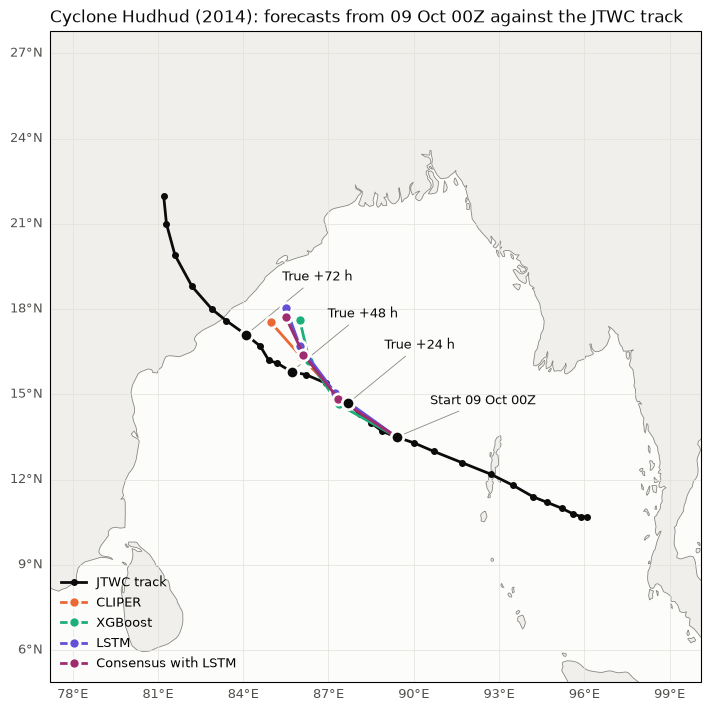

In [12]:
MAP_MODELS = ["cliper", "xgboost", "lstm", CONSENSUS_LSTM_NAME]
on_the_map = forecasts[forecasts["model"].isin(MAP_MODELS)]


def errors_from(sid: str, start: pd.Timestamp) -> pd.DataFrame:
    """Return each model's error in km for one storm and start time."""
    chosen = scored[
        (scored["SID"] == sid) & (scored["init_time"] == start) & scored["model"].isin(MAP_MODELS)
    ]
    return chosen.pivot(index="lead_h", columns="model", values="error_km").round(1)[MAP_MODELS]


plot_forecasts(
    truth,
    on_the_map,
    sid=hudhud_sid,
    init_time=hudhud_start,
    title="Cyclone Hudhud (2014): forecasts from 09 Oct 00Z against the JTWC track",
);
errors_from(hudhud_sid, hudhud_start)

CLIPER was closest at every lead here: a storm moving steadily suits a straight line. All four forecasts run north of
the true track. The LSTM was furthest at +24 and +48 h, and XGBoost at +72 h, with `consensus_lstm` between its members.

### Cyclone Nanauk, 2014

Nanauk is a different kind of pick: notebook 03 chose this start for being CLIPER's worst 24 h miss on the validation
split. Because it's a worst case, it says nothing about the average. It shows what a hard storm looks like.

model,cliper,xgboost,lstm,consensus_lstm
lead_h,,,,
24,486.6,401.7,352.7,413.4
48,877.8,606.4,696.5,726.9
72,1101.6,615.0,843.5,852.8


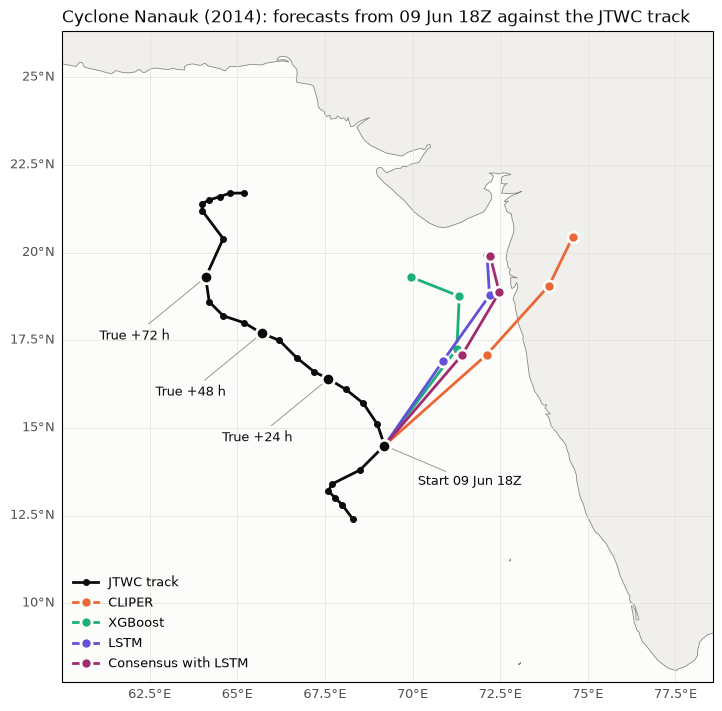

In [13]:
nanauk_sid = df[(df["NAME"] == "NANAUK") & (df["SEASON"] == 2014)]["SID"].iloc[0]
nanauk_start = pd.Timestamp("2014-06-09 18:00")

plot_forecasts(
    truth,
    on_the_map,
    sid=nanauk_sid,
    init_time=nanauk_start,
    title="Cyclone Nanauk (2014): forecasts from 09 Jun 18Z against the JTWC track",
    labels_below=True,  # the forecasts run through the space above the track
);
errors_from(nanauk_sid, nanauk_start)

The real storm went north-west into the Arabian Sea and then slowed, while every model sent it north-east towards India. The
LSTM was closest at +24 h and XGBoost beyond that, and all of them missed by more than 600 km at +72 h. An average can't help
much when every member misses on the same side.

## Conclusion

**Does the LSTM add anything beyond XGBoost? On its own, no. Inside an average, very little, and not measurably.**

| Question | Answer |
|---|---|
| Does the LSTM beat XGBoost? | **No.** It scores 0.89 against 3.38. It's behind at +24 h by 4.4% (interval −6.5 to −2.5) and level within the uncertainty beyond that. Its tracks are smoother, with the +48 h point 51 km from the midpoint of +24 and +72 h against XGBoost's 76, but not more accurate. |
| Does its longer history help? | **No, it hurts.** The same network given only 24 h scores 2.99, and is better at every lead. |
| Is the model itself better? | **No.** On the same 24 h of history it scores 2.99 against XGBoost's 3.38. |
| Does it help inside an average? | **Slightly at best.** `consensus_lstm` is 0.29 ahead of consensus (interval −0.34 to 0.91), which is level with zero. |

**Does the leader change? Yes: under the rule, `consensus_lstm` is now the primary model,** at 3.84 against consensus's 3.56.
Its mean error is 138, 315 and 487 km, against CLIPER's 145, 327 and 498 km.

**That lead isn't firm, and it should be read as a tie.** It holds with a second set of five seeds, but it depends on averaging
seeds, and it doesn't survive nested cross-validation, where the two are level at 3.44 and 3.50. Most of the lead came from choosing
the LSTM's settings on the same storms. The rule decides on the plain score, by design, so the choice stands and isn't reopened.
Both models get their own test interval anyway.

| Lead time | Does a model clearly beat CLIPER? |
|---|---|
| +24 h | **Yes.** XGBoost (6.1%), `consensus_lstm` (5.4%) and consensus (4.9%) all do. |
| +48 h | **Yes, for the two consensus models** (3.8% and 3.4%). |
| +72 h | **No.** `consensus_lstm` is ahead by 2.3%, with an interval that reaches zero (0.0 to 4.4%). |

This is the same picture as notebook 04, and a more flexible model didn't change it. These models see only a storm's own
past, which says less and less as the range grows, and giving the LSTM three days of it didn't help. What steers a storm over
three days is the wind around it, which none of them knows about, and which the AI weather models in Project 3 work from.

**Scope.** These results are for JTWC-warned systems in the North Indian Ocean, 1980–2017, measured across seasons in both directions,
so a model can learn from later seasons than it forecasts. The test split is the fair check on that, and it stays locked. West Pacific
pretraining may still change the race.

## Fit the final models

For the end of Project 1, every model with something to fit is refitted on all of 1980–2017 and saved: CLIPER, and 5
seeds each of XGBoost, `xgb_residual` and the LSTM. Both consensus models are worked out from the forecasts. The
LSTM's early stopping watches about 15% of those same storms, so nothing from test is involved.

They aren't scored here. They've seen every one of these storms, so a score would mean nothing, and the
cross-validated numbers above stand in for them.

Reloading must give exactly the same forecasts. The check below uses development storms, since this notebook
makes no test forecast.

In [14]:
final = final_model.fit_final_models(
    rows,
    truth,
    sequences,
    xgboost_settings,
    residual_settings,
    lstm_settings,
    device,
    lstm_device,
    lstm_checkpoints=final_dir / final_model.LSTM_DIR,
    resume=RESUME,
)
final_model.save_final_models(
    final,
    pd.read_csv(final_dir / "search_xgboost.csv"),
    pd.read_csv(final_dir / "search_residual.csv"),
    lstm_search,
)

reloaded = final_model.load_final_models()
same_forecasts = final_model.final_forecasts(final, rows, sequences).equals(
    final_model.final_forecasts(reloaded, rows, sequences)
)
print(f"LSTM seeds: {list(final.lstm)}, best epochs {[model.best_epoch for model in final.lstm.values()]}")
print(f"Reloaded models give identical forecasts: {same_forecasts}")

Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\seed42
Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\seed43


Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\seed44
Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\seed45


Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\seed46
Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\residual\seed42
Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\residual\seed43


Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\residual\seed44
Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\residual\seed45
Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\residual\seed46
Saved 5 networks to D:\Cyclone_proj\data\models\xgboost_final\lstm


LSTM seeds: [42, 43, 44, 45, 46], best epochs [5, 3, 8, 6, 8]
Reloaded models give identical forecasts: True


## Rehearse test day

Test is scored once, so test day should only run code that has already been tested. A bug that first shows up on test
has no good way out: fixing it and scoring again is a second look at the exam, and leaving it in means reporting a
wrong number.

So the whole path runs here first, on the real development seasons, with the saved models. It has to give exactly the rows
and cases cross-validation used, for all seven models.

**This prints counts, not errors.** The final models have seen all of these storms, so their errors would look far better
than they are, and would mean nothing. The rehearsal checks that the code works, not how good the models are.

`score_final_models` refuses 2018–2024 unless it's called with `confirm_test=True`. It isn't called on those seasons here.

In [15]:
development_seasons = range(FOLD_SEASONS[0][0], FOLD_SEASONS[-1][1] + 1)

same_rows = final_scoring.rows_for_seasons(df, development_seasons).equals(rows)
print(f"Rows match the cross-validation rows: {same_rows}\n")

rehearsal = final_scoring.score_final_models(df, development_seasons)

keys = ["model", "SID", "init_time", "lead_h"]
measured = scored.dropna(subset=["error_km"])
rehearsed = rehearsal.dropna(subset=["error_km"])
same_cases = set(map(tuple, measured[keys].to_numpy())) == set(map(tuple, rehearsed[keys].to_numpy()))
print(f"\nSame cases as cross-validation: {same_cases}\n")
print(rehearsed.groupby(["model", "lead_h"]).size().unstack().to_string())

Rows match the cross-validation rows: True



cliper: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
consensus: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
consensus_lstm: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
lstm: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
persistence: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
xgb_residual: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
xgboost: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth



Same cases as cross-validation: True

lead_h            24    48    72
model                           
cliper          2953  2209  1580
consensus       2953  2209  1580
consensus_lstm  2953  2209  1580
lstm            2953  2209  1580
persistence     2953  2209  1580
xgb_residual    2953  2209  1580
xgboost         2953  2209  1580
